# Compute Liveability for Each Suburb

Liveability is built from suburb-level median distances to amenities (and crime rate). Every feature is preferred to be small for good liveability, so the pipeline is:

1. Convert distance to the CBD from kilometres to metres so that all distance features share the same units.
2. Take the median value for each feature within each suburb.
3. Apply `log10(1 + x)` to reduce right skew (the `+ 1` keeps zero distances valid).
4. Standardise each log median across suburbs (mean 0, sample variance 1) so that no feature outweighs another purely through its scale.
5. Combine the features using a weighted sum.
6. Flip the direction and rescale so that higher means more liveable.

## Imports
Libraries used to aggregate, log-transform, standardise and plot the data.

In [84]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### Read in Final Parquet Data

In [85]:
PARQUET_PATH = (
    "../rea_data/analysis/rental_data_merged_final/"
    "rentals_final.parquet"
)

df = pd.read_parquet(PARQUET_PATH)
df.shape

(12316, 120)

In [86]:
list(df.columns)

['lat',
 'lon',
 'listing_id',
 'suburb',
 'weekly_rent',
 'date_listed',
 'bedrooms',
 'bathrooms',
 'carspaces',
 'property_type',
 'feat_built_in_wardrobes',
 'feat_heating',
 'feat_dishwasher',
 'feat_secure_parking',
 'feat_internal_laundry',
 'feat_air_conditioning',
 'feat_balcony___deck',
 'feat_gas',
 'feat_floorboards',
 'feat_bath',
 'feat_intercom',
 'feat_ensuite',
 'feat_fully_fenced',
 'feat_study',
 'feat_furnished',
 'feat_split_system_air_conditioning',
 'feat_pets_allowed',
 'feat_close_to_shops',
 'feat_split_system_heating',
 'feat_close_to_transport',
 'feat_close_to_schools',
 'feat_remote_garage',
 'feat_shed',
 'feat_ducted_heating',
 'feat_garden___courtyard',
 'feat_gym',
 'feat_outdoor_entertainment_area',
 'feat_balcony',
 'feat_broadband_internet_access',
 'feat_alarm_system',
 'feat_swimming_pool',
 'feat_courtyard',
 'feat_solar_panels',
 'feat_fireplaces',
 'feat_pool_spa_count_0',
 'feat_bathtub',
 'feat_ensuites',
 'feat_carpeted',
 'feat_gas_applianc

## Convert distance to CBD to metres

Every other distance feature is in metres, but `dist_to_cbd_km_driving` is in kilometres. The `+ 1` in `log10(1 + x)` is negligible for values in the hundreds or thousands (metres) but not for values like 0.5 (km), so the CBD distance is converted to metres first. This only adds a column in memory; the parquet file is untouched.

In [87]:
df["dist_to_cbd_m_driving"] = df["dist_to_cbd_km_driving"] * 1000

## Standardised log median by suburb

Given a feature column (a distance in metres, or crime rate), this function:

1. Takes the median value for each suburb.
2. Applies `log10(1 + x)` to the medians. The values here are in the hundreds to hundreds of thousands, so the `+ 1` barely changes the shape but makes zero values valid.
3. Standard scales the log medians across suburbs to mean 0 and s² = 1 (sample variance, `ddof=1`).
4. Returns a Series indexed by suburb.

Standardising across suburbs (not properties) means each suburb counts once. Higher values mean the suburb is further from the amenity (or has a higher crime rate) than average.

In [88]:
def standardised_log_median_by_suburb(
    df: pd.DataFrame,
    feature_column: str,
    suburb_column: str = "suburb",
) -> pd.Series:
    """Return each suburb's standardised log10(1 + median) value.

    Higher values mean the suburb is further away (or has a higher
    crime rate) than average.
    """
    
    median_values = df.groupby(suburb_column)[feature_column].median()
    log_median_values = np.log10(1 + median_values)

    return (
        log_median_values - log_median_values.mean()
    ) / log_median_values.std(ddof=1)

## Feature weights

One weight per feature in the liveability calculation. The weights are determined by the category weights used by the Economist Intelligence Unit Global Liveability Index. Because every standardised feature will have mean 0 and variance 1, these weights now directly reflect relative importance.

Category weights: Stability (25%), Culture & Environment (25%), Healthcare (20%), Infrastructure (20%), Education (10%). The weights below sum to 1, as the `weights.sum()` output confirms.

Distance to the CBD uses the metre version created above. Medical centre distance is currently excluded (commented out). If it is re-enabled, the weights must be rebalanced (for example, by splitting the Healthcare weight with the hospital) so that they still sum to 1.

In [89]:
weights = pd.Series(
    {
        "school_primary_road_distance_m": 0.05, # Education
        "school_secondary_road_distance_m": 0.05,  # Education
        "hospital_road_distance_m": 0.13,  # Healthcare
        "medical_doctors_road_distance_m": 0.07, # Healthcare
        "crime_rate": 0.25, # Stability
        "sports_rec_road_distance_m": 0.075, # Culture & Environment
        "park_local_road_distance_m": 0.075, # Culture & Environment
        "shopping_centre_road_distance_m": 0.1, # Culture & Environment
        "bus_stops_PTV_road_distance_m": 0.05, # Infrastructure
        "train_stations_PTV_road_distance_m": 0.1, # Infrastructure
        "dist_to_cbd_km_driving": 0.05, # Infrastructure
    }
)
weights.sum()

np.float64(1.0)

## Effect of the log transform

For each feature, the left panel shows the distribution of raw suburb medians and the right panel shows the distribution of `log10(1 + suburb median)`. Distance features are in metres; crime rate is not a distance, so its axis labels say so. The skewness of each distribution is in the panel title (0 means symmetric; large positive values mean a long right tail). The log version should be much closer to symmetric.

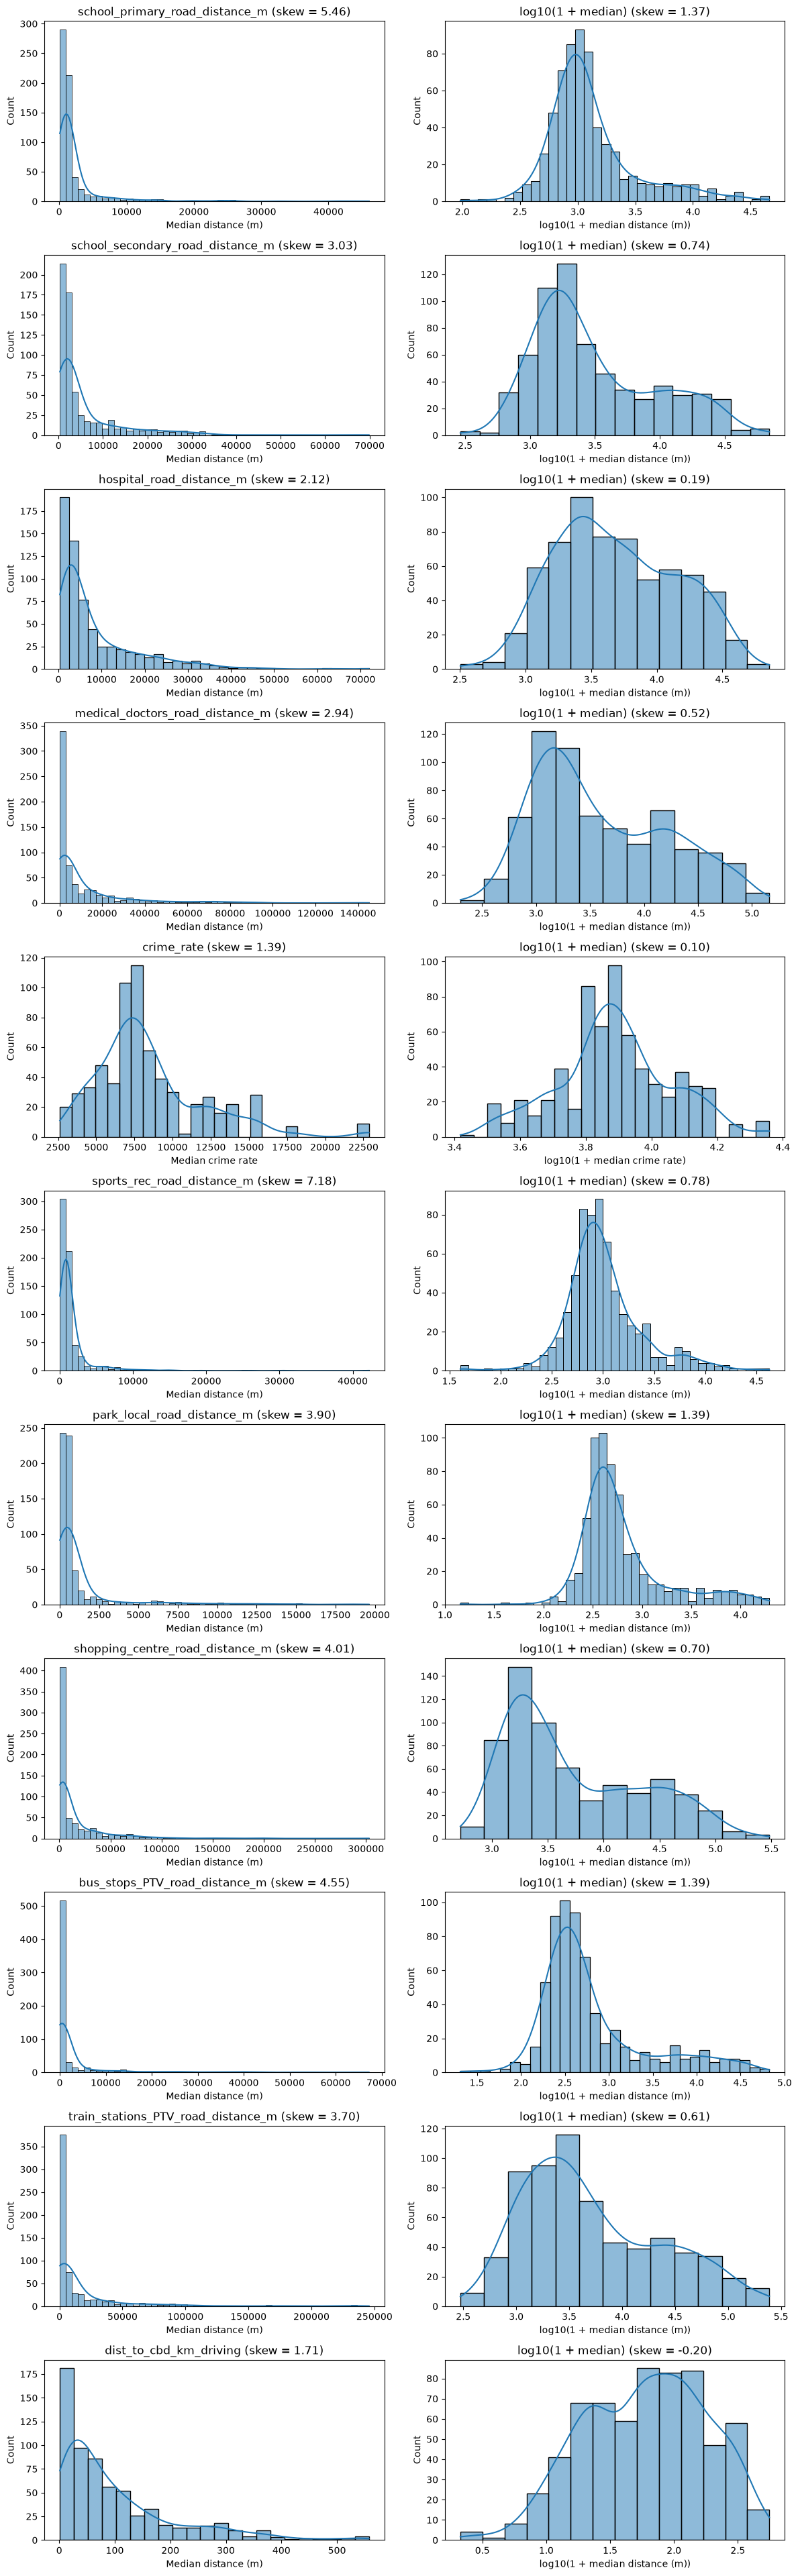

In [90]:
# Features that are not distances, with the text used in axis labels
NON_DISTANCE_LABELS = {"crime_rate": "crime rate"}

# group by suburb, compute median of each feature in liveability calculation
median_values = pd.DataFrame(
    {
        column: df.groupby("suburb")[column].median()
        for column in weights.index
    }
)

# apply log base 10 transform (+1 to ensure 0 distance doesn't fail)
log_median_values = np.log10(1 + median_values)

# all distributions will be visualised on the same plot window
fig, axes = plt.subplots(
    len(weights), 2, figsize=(12, 3.5 * len(weights))
)

for row, column in enumerate(weights.index):
    raw = median_values[column]
    logged = log_median_values[column]

    # set to non-distance label column, otherwise revert to distance (m)
    label = NON_DISTANCE_LABELS.get(column, "distance (m)")

    # kde plot of distribution of raw medians
    sns.histplot(raw, kde=True, ax=axes[row, 0])
    axes[row, 0].set_title(f"{column} (skew = {raw.skew():.2f})")
    axes[row, 0].set_xlabel(f"Median {label}")

    # kde plot of distribution of logged medians, alongside the raw medians
    sns.histplot(logged, kde=True, ax=axes[row, 1])
    axes[row, 1].set_title(
        f"log10(1 + median) (skew = {logged.skew():.2f})"
    )
    axes[row, 1].set_xlabel(f"log10(1 + median {label})")

plt.tight_layout()
plt.show()

## Standardise every feature

Builds a DataFrame with one row per suburb and one column of standardised log median values per feature.

In [91]:
standardised_features = pd.DataFrame(
    {
        column: standardised_log_median_by_suburb(df, column)
        for column in weights.index
    }
)
standardised_features.head()

,school_primary_road_distance_m,school_secondary_road_distance_m,hospital_road_distance_m,medical_doctors_road_distance_m,crime_rate,sports_rec_road_distance_m,park_local_road_distance_m,shopping_centre_road_distance_m,bus_stops_PTV_road_distance_m,train_stations_PTV_road_distance_m,dist_to_cbd_km_driving
suburb,,,,,,,,,,,
ABBOTSFORD,-0.743639,-1.008844,-1.166887,-0.938408,1.735194,-1.238835,-0.625732,-1.380771,-0.065094,-0.929634,-1.610081
ABERFELDIE,-0.654635,-1.653476,-0.750786,-0.522448,-0.049112,-1.947986,0.226387,-0.489097,-1.529145,-0.656511,-1.253434
AIRPORT WEST,-0.352024,-0.165565,-0.169310,-0.169382,-0.049112,-0.241880,-0.413766,-0.937283,-0.765470,0.067143,-0.968866
ALBANVALE,-0.748689,-0.025962,-0.369809,-0.557819,0.479371,-0.326443,-0.560575,-0.918991,-0.464789,-0.353208,-0.675326
ALBERT PARK,-1.110525,-0.788421,-0.254648,-1.623358,1.495003,-0.963225,-1.198150,-0.851627,-0.143900,-0.499296,-3.036113


## Weighted sum

Combines the standardised features using the weights. Since every feature is worse when large, a **higher** weighted sum means the suburb is **further** from amenities or has **more** crime, so it is **less** liveable.

In [92]:
# element-wise multiplication between each col above and weights series
# Sum across features (axis=1) to get one weighted score per suburb
weighted_sum = standardised_features.mul(weights).sum(axis=1) 

## Flip and rescale to a liveability score

The direction is flipped once, at the end, so that higher means more liveable. Two versions are produced:

- **`liveability`**: min-max scaled to 0-1, where 1 is the best suburb and 0 is the worst. This is relative to the best and worst suburbs, not literally "% liveable", and a single extreme suburb compresses the rest.
- **`liveability_percentile`**: percentile rank, where 0.8 means the suburb is more liveable than 80% of suburbs. This is robust to outliers and easier to explain.

In [93]:
weighted_sum_range = weighted_sum.max() - weighted_sum.min()
liveability = (weighted_sum.max() - weighted_sum) / weighted_sum_range
liveability_percentile = (-weighted_sum).rank(pct=True)

suburb_scores = pd.DataFrame(
    {
        "liveability": liveability,
        "liveability_percentile": liveability_percentile,
    }
).reset_index()

suburb_scores.sort_values("liveability", ascending=False).head(10)

,suburb,liveability,liveability_percentile
202,ELSTERNWICK,1.000000,1.000000
581,TRAVANCORE,0.988863,0.998447
226,GARDENVALE,0.986529,0.996894
82,BRIGHTON,0.966147,0.995342
184,DONCASTER,0.965733,0.993789
263,HAWTHORN,0.957909,0.992236
264,HAWTHORN EAST,0.944153,0.990683
505,SANDRINGHAM,0.941860,0.989130
233,GLEN HUNTLY,0.938154,0.987578
257,HAMPTON,0.931083,0.986025
